# OULAD EDA — LearnGuard M1

**Mục đích:** khám phá sơ bộ 7 bảng OULAD để chốt schema + chính sách chất lượng dữ liệu cho giai đoạn **M1 (Ingestion & Schema Contracts)**.

**Dữ liệu:** `data/oulad/archive/*.csv` (nguồn: Open University Learning Analytics Dataset, 22 khoá học, 4 kỳ 2013B/J – 2014B/J).

**Kết luận nhanh** (chi tiết ở cuối notebook):
- `id_student` **không** là PK của `studentInfo` → PK thực sự là `(code_module, code_presentation, id_student)`
- Referential integrity **hoàn hảo** (0 orphan trên 9 quan hệ FK)
- Cần policy cho: `imd_band` null 3.4%, `score` null 0.1%, `assessments.date` null (Exam), duplicate key trong `studentVle`, `date` âm trong `studentVle`
- `studentVle` có **10.6M dòng** → nên convert Parquet ngay từ ingestion

## 0 · Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("../data/oulad/archive")

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

TABLES = [
    "courses",
    "assessments",
    "vle",
    "studentInfo",
    "studentRegistration",
    "studentAssessment",
    "studentVle",
]

dfs = {t: pd.read_csv(DATA / f"{t}.csv") for t in TABLES}
print("Đã load:", ", ".join(f"{t} ({len(df):,} dòng)" for t, df in dfs.items()))

Đã load: courses (22 dòng), assessments (206 dòng), vle (6,364 dòng), studentInfo (32,593 dòng), studentRegistration (32,593 dòng), studentAssessment (173,912 dòng), studentVle (10,655,280 dòng)


## 1 · Tổng quan từng bảng

Kiểm tra dtype, số null, số giá trị duy nhất của mọi cột — đầu vào trực tiếp cho schema contracts.

In [2]:
for t in TABLES:
    df = dfs[t]
    print(f"\n{'=' * 66}\n[{t}] shape = {df.shape}\n{'=' * 66}")
    info = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "nulls": df.isna().sum(),
        "null_%": (df.isna().mean() * 100).round(2),
        "nunique": df.nunique(),
    })
    print(info.to_string())


[courses] shape = (22, 3)
                            dtype  nulls  null_%  nunique
code_module                   str      0     0.0        7
code_presentation             str      0     0.0        4
module_presentation_length  int64      0     0.0        7

[assessments] shape = (206, 6)
                     dtype  nulls  null_%  nunique
code_module            str      0    0.00        7
code_presentation      str      0    0.00        4
id_assessment        int64      0    0.00      206
assessment_type        str      0    0.00        3
date               float64     11    5.34       74
weight             float64      0    0.00       24

[vle] shape = (6364, 6)
                     dtype  nulls  null_%  nunique
id_site              int64      0    0.00     6364
code_module            str      0    0.00        7
code_presentation      str      0    0.00        4
activity_type          str      0    0.00       20
week_from          float64   5243   82.39       30
week_to            fl

                   dtype  nulls  null_%  nunique
code_module          str      0     0.0        7
code_presentation    str      0     0.0        4
id_student         int64      0     0.0    26074
id_site            int64      0     0.0     6268
date               int64      0     0.0      295
sum_click          int64      0     0.0      498


## 1.5 · Schema ban đầu & mô tả các trường

Bảng mô tả chuẩn theo **tài liệu chính thức của OULAD** (Kuzilek et al., 2017), đối chiếu với dtype + % null **thực tế** trong dữ liệu vừa nạp. Đơn vị ngày = số ngày tính từ ngày khai giảng (ngày 0); ngày âm = trước khai giảng.

Chú thích vai trò: **PK** = khóa chính · **FK** = khóa ngoại · **LABEL** = nhãn dự đoán (M4)

In [3]:
SCHEMA_DESC = {
    "courses": [
        ("code_module", "PK*", "Mã học phần (AAA–GGG, 7 học phần)"),
        ("code_presentation", "PK*", "Kỳ học: 2013B, 2013J, 2014B, 2014J (B = bắt đầu tháng 2, J = tháng 10)"),
        ("module_presentation_length", "", "Độ dài kỳ học (số ngày, 234–269)"),
    ],
    "assessments": [
        ("id_assessment", "PK", "Mã bài đánh giá, duy nhất toàn cục"),
        ("code_module", "FK", "→ courses.code_module"),
        ("code_presentation", "FK", "→ courses.code_presentation"),
        ("assessment_type", "", "TMA = chấm bởi tutor · CMA = chấm máy · Exam = thi cuối kỳ"),
        ("date", "", "Ngày diễn ra đánh giá (ngày 0 = khai giảng). Null 11 dòng = Exam không công bố ngày"),
        ("weight", "", "Trọng số điểm 0–100. Exam luôn 100; tổng TMA+CMA mỗi kỳ = 100"),
    ],
    "vle": [
        ("id_site", "PK", "Mã tài nguyên VLE, duy nhất toàn cục"),
        ("code_module", "FK", "→ courses.code_module"),
        ("code_presentation", "FK", "→ courses.code_presentation"),
        ("activity_type", "", "Loại tài nguyên: resource, subpage, oucontent, url, forumng, quiz... (20 loại)"),
        ("week_from", "", "Tuần bắt đầu dự kiến của tài nguyên — null 82% → loại khỏi feature catalog"),
        ("week_to", "", "Tuần kết thúc dự kiến — null 82% → loại khỏi feature catalog"),
    ],
    "studentInfo": [
        ("code_module", "FK", "→ courses.code_module"),
        ("code_presentation", "FK", "→ courses.code_presentation"),
        ("id_student", "FK*", "Mã sinh viên — KHÔNG unique (1 SV học nhiều kỳ); PK thực = (module, presentation, student)"),
        ("gender", "", "Giới tính: M / F"),
        ("region", "", "Vùng địa lý tại Anh/Bắc Ireland (13 vùng)"),
        ("highest_education", "", "Trình độ cao nhất: A Level, Lower Than A Level, HE Qualification, No Formal quals, Post Graduate"),
        ("imd_band", "", "Chỉ số nghèo đa chiều (IMD) của khu vực, chia 10 nhóm 0-10% → 90-100%. Null 3.41%"),
        ("age_band", "", "Nhóm tuổi: 0-35, 35-55, 55<="),
        ("num_of_prev_attempts", "", "Số lần học lại học phần này trước đó (0–6)"),
        ("studied_credits", "", "Tổng số tín chỉ sinh viên đang học trong kỳ (0–655)"),
        ("disability", "", "Khuyết tật: Y / N"),
        ("final_result", "LABEL", "Kết quả: Pass, Fail, Withdrawn, Distinction — nhãn cho model M4"),
    ],
    "studentRegistration": [
        ("code_module", "PK/FK", "→ courses (cùng code_presentation, id_student tạo PK composite)"),
        ("code_presentation", "PK/FK", "→ courses"),
        ("id_student", "PK/FK", "→ studentInfo"),
        ("date_registration", "", "Ngày đăng ký (âm = đăng ký trước khai giảng). Null 45 dòng"),
        ("date_unregistration", "", "Ngày rút lui. Null 69% = không rút lui (học đến hết) — null là HỢP LỆ"),
    ],
    "studentAssessment": [
        ("id_assessment", "FK", "→ assessments.id_assessment"),
        ("id_student", "FK", "→ studentInfo.id_student"),
        ("date_submitted", "", "Ngày nộp bài (so với khai giảng)"),
        ("is_banked", "", "1 = điểm được chuyển từ kỳ học trước (đã đăng ký lại)"),
        ("score", "", "Điểm 0–100. Null 173 dòng = SV rút lui trước khi có điểm — hợp lệ nghiệp vụ, chú ý leakage M3"),
    ],
    "studentVle": [
        ("code_module", "FK", "→ courses.code_module"),
        ("code_presentation", "FK", "→ courses.code_presentation"),
        ("id_student", "FK", "→ studentInfo.id_student"),
        ("id_site", "FK", "→ vle.id_site"),
        ("date", "", "Ngày tương tác VLE; có thể ÂM (min −25, click trước khai giảng). Bảng lớn nhất: 10.6M dòng"),
        ("sum_click", "", "Số lượt click của SV vào tài nguyên trong NGÀY đó. Nhiều dòng cùng (SV, site, ngày) → SUM khi aggregate"),
    ],
}

rows = []
for table, cols in SCHEMA_DESC.items():
    df = dfs[table]
    for col, role, desc in cols:
        rows.append({
            "bảng": table,
            "trường": col,
            "vai_trò": role or "—",
            "dtype_thực_tế": str(df[col].dtype),
            "null_%": f"{df[col].isna().mean() * 100:.2f}%",
            "mô_tả": desc,
        })

schema_df = pd.DataFrame(rows)
print(f"Tổng số trường: {len(schema_df)} trên {len(TABLES)} bảng")
schema_df

Tổng số trường: 43 trên 7 bảng


,bảng,trường,vai_trò,dtype_thực_tế,null_%,mô_tả
0,courses,code_module,PK*,str,0.00%,"Mã học phần (AAA–GGG, 7 học phần)"
1,courses,code_presentation,PK*,str,0.00%,"Kỳ học: 2013B, 2013J, 2014B, 2014J (B = bắt đầ..."
2,courses,module_presentation_length,—,int64,0.00%,"Độ dài kỳ học (số ngày, 234–269)"
3,assessments,id_assessment,PK,int64,0.00%,"Mã bài đánh giá, duy nhất toàn cục"
4,assessments,code_module,FK,str,0.00%,→ courses.code_module
5,assessments,code_presentation,FK,str,0.00%,→ courses.code_presentation
6,assessments,assessment_type,—,str,0.00%,TMA = chấm bởi tutor · CMA = chấm máy · Exam =...
7,assessments,date,—,float64,5.34%,Ngày diễn ra đánh giá (ngày 0 = khai giảng). N...
8,assessments,weight,—,float64,0.00%,Trọng số điểm 0–100. Exam luôn 100; tổng TMA+C...
9,vle,id_site,PK,int64,0.00%,"Mã tài nguyên VLE, duy nhất toàn cục"


## 2 · Biến phân loại

Xác nhận miền giá trị (allowed values) của từng cột categorical — sẽ trở thành enum/rule trong schema.

In [4]:
CATS = {
    "courses": ["code_module", "code_presentation"],
    "assessments": ["code_module", "code_presentation", "assessment_type"],
    "studentInfo": ["gender", "region", "highest_education", "imd_band", "age_band", "disability", "final_result"],
    "vle": ["code_module", "code_presentation", "activity_type"],
}

for t, cols in CATS.items():
    print(f"\n{'=' * 66}\n[{t}]\n{'=' * 66}")
    for c in cols:
        print(f"\n{c} — {dfs[t][c].nunique(dropna=True)} giá trị:")
        print(dfs[t][c].value_counts(dropna=False).head(15).to_string())


[courses]

code_module — 7 giá trị:
code_module
BBB    4
DDD    4
FFF    4
EEE    3
GGG    3
AAA    2
CCC    2

code_presentation — 4 giá trị:
code_presentation
2014J    7
2013J    6
2014B    6
2013B    3

[assessments]

code_module — 7 giá trị:
code_module
FFF    52
BBB    42
DDD    35
GGG    30
CCC    20
EEE    15
AAA    12

code_presentation — 4 giá trị:
code_presentation
2014J    57
2014B    57
2013J    53
2013B    39

assessment_type — 3 giá trị:
assessment_type
TMA     106
CMA      76
Exam     24

[studentInfo]

gender — 2 giá trị:
gender
M    17875
F    14718

region — 13 giá trị:
region
Scotland                3446
East Anglian Region     3340
London Region           3216
South Region            3092
North Western Region    2906
West Midlands Region    2582
South West Region       2436
East Midlands Region    2365
South East Region       2111
Wales                   2086
Yorkshire Region        2006
North Region            1823
Ireland                 1184

highest_education —

## 3 · Giá trị đáng ngờ

Các điểm cần policy rõ ràng trước khi implement ingestion:
1. `imd_band` — null thay vì `'?'` như một số bản OULAD khác
2. `score` null — sinh viên rút lui trước khi nộp/thi
3. `assessments.date` null — 11 đề thi Exam không công bố ngày
4. Trọng số tổng mỗi kỳ 100–300 (Exam tự mang weight 100)

In [5]:
si, sa, asm, sr = dfs["studentInfo"], dfs["studentAssessment"], dfs["assessments"], dfs["studentRegistration"]
svle, vle = dfs["studentVle"], dfs["vle"]

print("imd_band == '?':", (si["imd_band"] == "?").sum())
print("imd_band null :", si["imd_band"].isna().sum())
print("score null    :", sa["score"].isna().sum(), "| score ngoài [0,100]:", ((sa["score"] < 0) | (sa["score"] > 100)).sum())
print("asm date null :", asm["date"].isna().sum(), "(thuộc loại:", asm.loc[asm['date'].isna(), 'assessment_type'].unique(), ")")
print("asm date < 0  :", (asm["date"] < 0).sum())

imd_band == '?': 0
imd_band null : 1111
score null    : 173 | score ngoài [0,100]: 0
asm date null : 11 (thuộc loại: <ArrowStringArray>
['Exam']
Length: 1, dtype: str )
asm date < 0  : 0


In [6]:
print("Tổng weight theo kỳ (min..max):")
w = asm.groupby(["code_module", "code_presentation"])["weight"].sum()
print(w.describe().to_string())
print("\nSố assessment weight == 0:", (asm["weight"] == 0).sum())
print("date_unregistration null (chưa rút lui):", sr["date_unregistration"].isna().sum())
print("date_registration null               :", sr["date_registration"].isna().sum())
print("studentVle: date min/max =", svle["date"].min(), "/", svle["date"].max(), "→ có click TRƯỚC ngày khai giảng")
print("vle week_from/week_to null:", f"{vle['week_from'].isna().mean():.0%}", "→ gần như không dùng được làm feature")

Tổng weight theo kỳ (min..max):
count     22.000000
mean     195.454545
std       48.572702
min      100.000000
25%      200.000000
50%      200.000000
75%      200.000000
max      300.000000

Số assessment weight == 0: 56
date_unregistration null (chưa rút lui): 22521
date_registration null               : 45
studentVle: date min/max = -25 / 269 → có click TRƯỚC ngày khai giảng
vle week_from/week_to null: 82% → gần như không dùng được làm feature


## 4 · Kiểm tra primary key

⚠️ **Phát hiện quan trọng nhất:** `studentInfo.id_student` bị trùng 3.808 dòng vì một sinh viên học nhiều kỳ → **PK thực sự là `(code_module, code_presentation, id_student)`**.

`studentVle` trùng key `(module, pres, student, site, date)` — **BẢN SỬA sau verify M1 (2026-10-26):** 787,170 dòng là bản sao y hệt toàn cột (artifact xuất trùng) → được **dedupe ở M1**; phần còn lại trùng key nhưng `sum_click` khác nhau là **sự kiện click riêng biệt** → giữ nguyên, aggregate sang cutoff day-27 (M2) bằng **SUM `sum_click`**.

In [7]:
print("PK uniqueness:")
for t, pk in [
    ("courses", ["code_module", "code_presentation"]),
    ("assessments", ["id_assessment"]),
    ("vle", ["id_site"]),
    ("studentRegistration", ["code_module", "code_presentation", "id_student"]),
]:
    print(f"  {t} PK={pk}: duplicated = {dfs[t].duplicated(subset=pk).sum()}")

print(f"  studentInfo PK=[id_student]: duplicated = {si['id_student'].duplicated().sum()}  ← KHÔNG unique")
print(f"  studentAssessment (id_student,id_assessment): duplicated = {sa.duplicated(subset=['id_student', 'id_assessment']).sum()}")
print(f"  studentVle (module,pres,student,site,date): duplicated = {svle.duplicated(subset=['code_module', 'code_presentation', 'id_student', 'id_site', 'date']).sum():,}")

PK uniqueness:
  courses PK=['code_module', 'code_presentation']: duplicated = 0
  assessments PK=['id_assessment']: duplicated = 0
  vle PK=['id_site']: duplicated = 0
  studentRegistration PK=['code_module', 'code_presentation', 'id_student']: duplicated = 0
  studentInfo PK=[id_student]: duplicated = 3808  ← KHÔNG unique
  studentAssessment (id_student,id_assessment): duplicated = 0


  studentVle (module,pres,student,site,date): duplicated = 2,195,960


In [8]:
dups = si[si["id_student"].duplicated(keep=False)].sort_values("id_student")
print(f"Số student xuất hiện >1 dòng: {dups['id_student'].nunique()} (tổng {len(dups)} dòng) — ví dụ 4 student:")
print(dups.head(8).to_string())

Số student xuất hiện >1 dòng: 3538 (tổng 7346 dòng) — ví dụ 4 student:
      code_module code_presentation  id_student gender               region      highest_education imd_band age_band  num_of_prev_attempts  studied_credits disability final_result
14395         DDD             2013J        8462      M        London Region       HE Qualification   30-40%     55<=                     0               90          N    Withdrawn
17560         DDD             2014J        8462      M        London Region       HE Qualification   30-40%     55<=                     1               60          N    Withdrawn
16332         DDD             2014B       24213      F  East Anglian Region  A Level or Equivalent   40-50%     0-35                     1               60          N         Pass
13091         DDD             2013B       24213      F  East Anglian Region  A Level or Equivalent   40-50%     0-35                     0               90          N    Withdrawn
4752          BBB            

## 5 · Referential integrity

Kết quả tốt: **0 orphan trên cả 9 quan hệ khóa ngoại** → ingestion chỉ cần chạy check phòng ngừa, không cần repair.

In [9]:
course_keys = dfs["courses"].set_index(["code_module", "code_presentation"]).index
student_ids = set(si["id_student"])
assess_ids = set(asm["id_assessment"])
site_ids = set(vle["id_site"])

checks = [
    ("assessments → courses", ~asm.set_index(["code_module", "code_presentation"]).index.isin(course_keys)),
    ("vle → courses", ~vle.set_index(["code_module", "code_presentation"]).index.isin(course_keys)),
    ("studentRegistration → courses", ~sr.set_index(["code_module", "code_presentation"]).index.isin(course_keys)),
    ("studentVle → courses", ~svle.set_index(["code_module", "code_presentation"]).index.isin(course_keys)),
    ("studentRegistration → studentInfo", ~sr["id_student"].isin(student_ids)),
    ("studentAssessment → studentInfo", ~sa["id_student"].isin(student_ids)),
    ("studentVle → studentInfo", ~svle["id_student"].isin(student_ids)),
    ("studentAssessment → assessments", ~sa["id_assessment"].isin(assess_ids)),
    ("studentVle → vle", ~svle["id_site"].isin(site_ids)),
]
for name, mask in checks:
    print(f"{name}: orphan = {int(mask.sum())}")

assessments → courses: orphan = 0
vle → courses: orphan = 0
studentRegistration → courses: orphan = 0
studentVle → courses: orphan = 0
studentRegistration → studentInfo: orphan = 0
studentAssessment → studentInfo: orphan = 0
studentVle → studentInfo: orphan = 0
studentAssessment → assessments: orphan = 0
studentVle → vle: orphan = 0


## 6 · Phân bố nhãn `final_result` (đầu vào cho M4)

Nếu nhãn nhị phân "at-risk" = `Fail` + `Withdrawn` → **~52.9% positive**, dataset khá cân → tốt cho baseline Logistic Regression (M4).

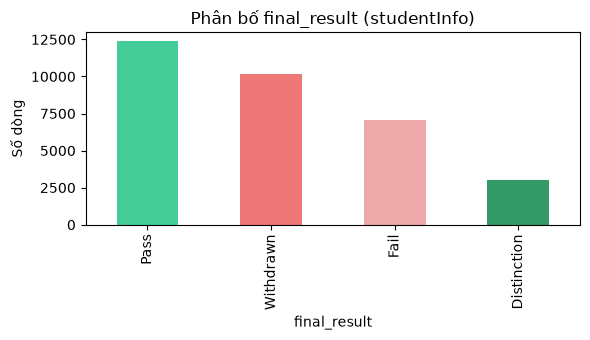

at-risk (Fail + Withdrawn) = 17,208/32,593 = 52.8%


In [10]:
vc = si["final_result"].value_counts()
ax = vc.plot(kind="bar", color=["#4c9", "#e77", "#eaa", "#396"], figsize=(6, 3.5))
ax.set_title("Phân bố final_result (studentInfo)")
ax.set_ylabel("Số dòng")
plt.tight_layout()
plt.show()

at_risk = vc["Fail"] + vc["Withdrawn"]
print(f"at-risk (Fail + Withdrawn) = {at_risk:,}/{vc.sum():,} = {at_risk / vc.sum():.1%}")

## 7 · Kết luận → quyết định schema M1

| # | Phát hiện | Quyết định đề xuất |
|---|---|---|
| 1 | `id_student` không unique trong `studentInfo` (3.808 dòng trùng) | **PK = `(code_module, code_presentation, id_student)`** — sửa schema contracts |
| 2 | `imd_band` null 3.41% | Giữ `pd.NA` + cờ `imd_band_missing`, **không drop** |
| 3 | `score` null 173 dòng (rút lui giữa kỳ) | Null là *hợp lệ về nghiệp vụ*; phải nằm trong leakage audit M3 |
| 4 | `assessments.date` null cho 11 đề Exam | Exam không ngày → **không tính** vào feature trước cutoff day-27 (M2) |
| 5 | `studentVle` trùng key 5 cột — trộn 2 bản chất | **BẢN SỬA sau verify M1:** 787,170 dòng là bản sao y hệt toàn cột (artifact) → **M1 dedupe**; phần trùng key nhưng `sum_click` khác là sự kiện click riêng → **M2 SUM `sum_click`** |
| 6 | `studentVle` có `date` âm (min −25) | Cutoff logic M2 xử lý đúng biên: click trước khai giảng vẫn là dữ liệu "trước cutoff" |
| 7 | `studentVle` 10.6M dòng CSV | Ingestion convert sang **Parquet partitioned** ngay M1 |
| 8 | `vle.week_from/week_to` null 82% | Loại khỏi feature catalog |

**Việc tiếp theo:** cập nhật `src/learnguard/data/schema.py` theo bảng trên, rồi implement `OuladIngestionService` (load → validate → quarantine → source hash → Parquet).